In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../dataset/raw/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [4]:
print("Dataset Columns:")
print(df.columns.tolist())


Dataset Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [7]:
print("Fraud Distribution:")
print(df["isFraud"].value_counts())

Fraud Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


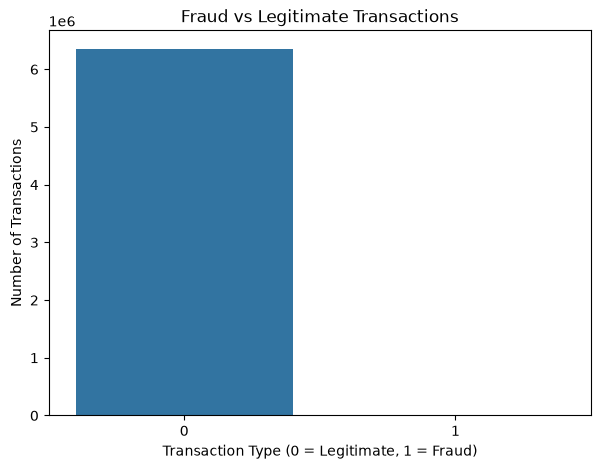

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="isFraud"
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Total Missing Values: 0


In [9]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [10]:
print("Statistical Summary:")

display(df.describe())

Statistical Summary:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


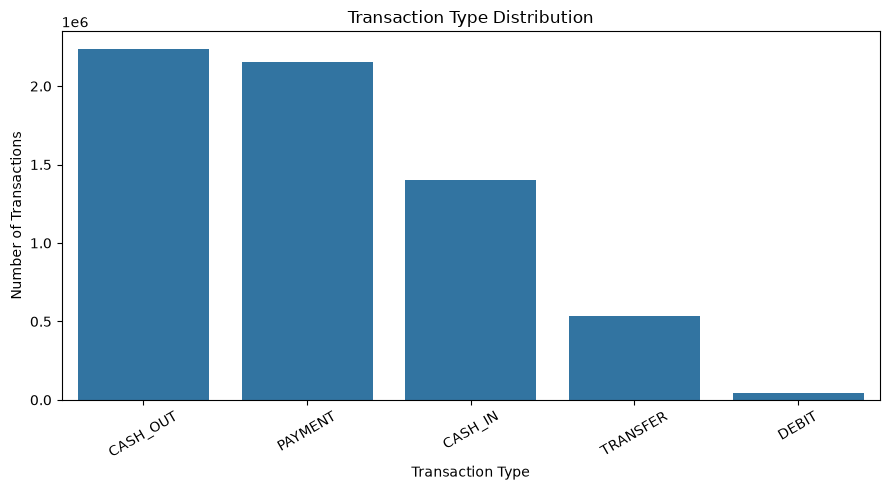

In [11]:
transaction_counts = df["type"].value_counts()

print(transaction_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="type",
    order=transaction_counts.index
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
fraud_by_type = df.groupby("type").agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum")
)

fraud_by_type["fraud_percentage"] = (
    fraud_by_type["fraud_transactions"] /
    fraud_by_type["total_transactions"]
) * 100

display(fraud_by_type)

,total_transactions,fraud_transactions,fraud_percentage
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.183955
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.768799


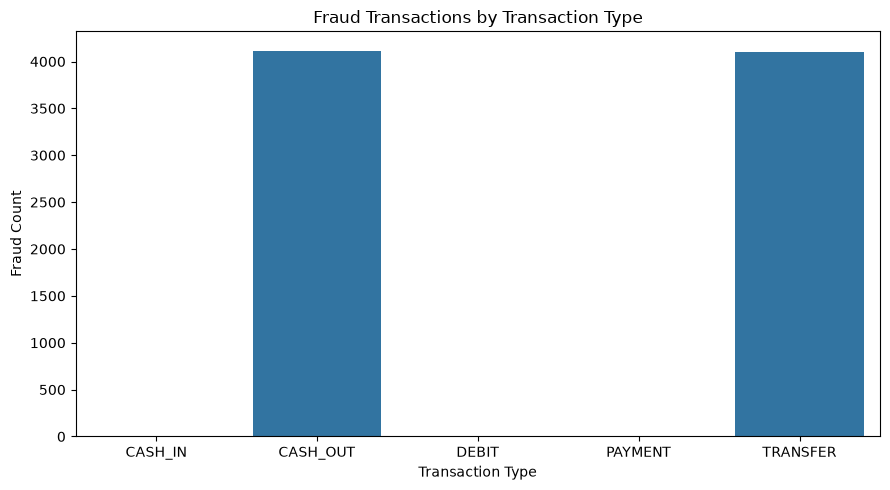

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fraud_by_type.reset_index(),
    x="type",
    y="fraud_transactions"
)

plt.title("Fraud Transactions by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Count")

plt.tight_layout()
plt.show()

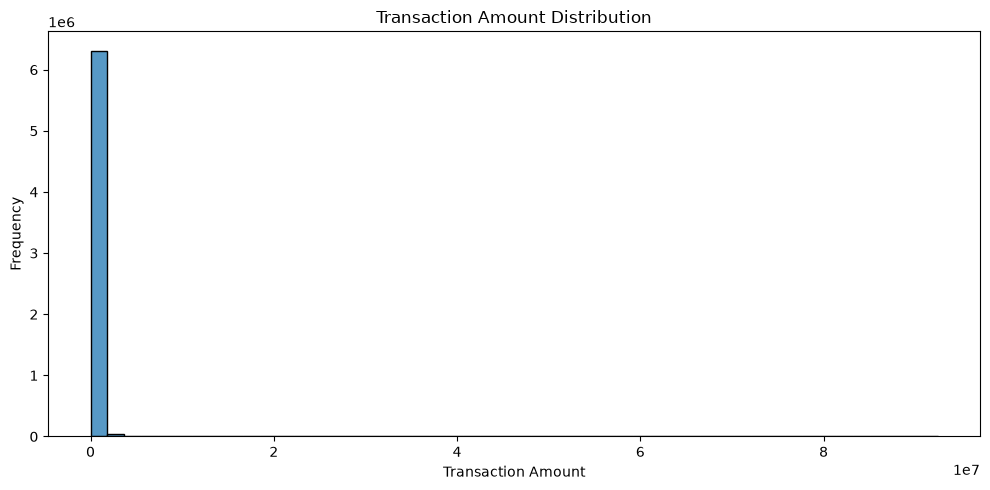

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="amount",
    bins=50
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

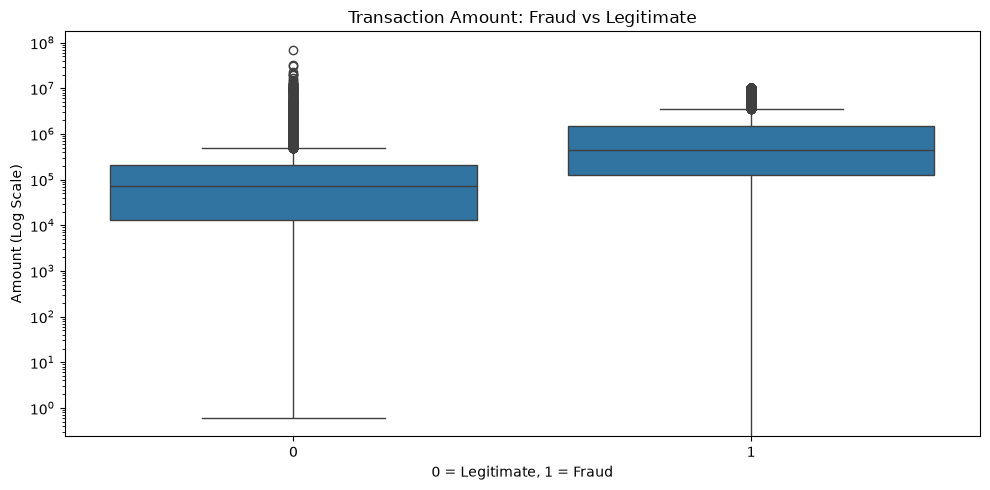

In [15]:
fraud_data = df[df["isFraud"] == 1]

normal_data = df[df["isFraud"] == 0].sample(
    n=50000,
    random_state=42
)

sample_data = pd.concat([
    fraud_data,
    normal_data
])

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sample_data,
    x="isFraud",
    y="amount"
)

plt.yscale("log")

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Amount (Log Scale)")

plt.tight_layout()
plt.show()

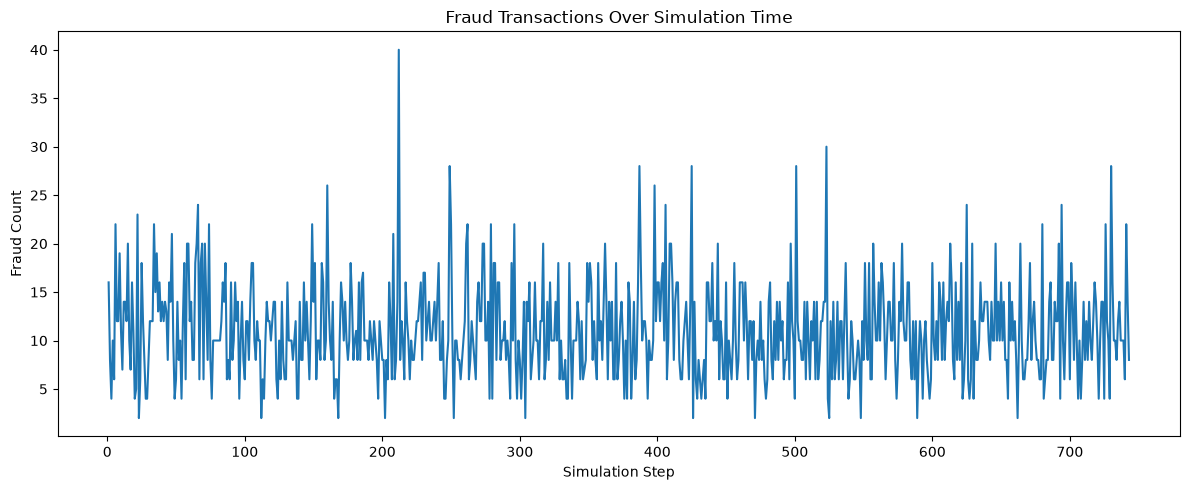

In [16]:
fraud_by_step = (
    df[df["isFraud"] == 1]
    .groupby("step")
    .size()
)

plt.figure(figsize=(12, 5))

fraud_by_step.plot()

plt.title("Fraud Transactions Over Simulation Time")
plt.xlabel("Simulation Step")
plt.ylabel("Fraud Count")

plt.tight_layout()
plt.show()